In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [24]:
import glob
import os
import kagglehub
import pandas as pd

# 1. Baixa a versão mais recente do dataset do Kaggle
path = kagglehub.dataset_download("alanvourch/tmdb-movies-daily-updates")

# 2. Localiza automaticamente o arquivo .csv dentro da pasta baixada
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Carregando:", csv_path)

# 3. Lê o CSV (low_memory=False evita avisos de tipos mistos em colunas grandes)
df = pd.read_csv(csv_path, low_memory=False)
print(f"Shape: {df.shape}")
df.head()

Carregando: C:\Users\Aline M\.cache\kagglehub\datasets\alanvourch\tmdb-movies-daily-updates\versions\1069\TMDB_all_movies.csv
Shape: (1277405, 30)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10105.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8934.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2933.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Robert Rodriguez, Alexandre Rockwell, Allison ...","Andrzej Sekula, Guillermo Navarro, Rodrigo Gar...","Quentin Tarantino, Allison Anders, Alexandre R...","Quentin Tarantino, Alexandre Rockwell, Lawrenc...",Combustible Edison,6.7,118135.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Marilyn Vance, Lloyd Segan",Alan Silvestri,6.6,21514.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [25]:
df.shape

(1277405, 30)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1277405 entries, 0 to 1277404
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1277405 non-null  int64  
 1   title                    1277391 non-null  str    
 2   vote_average             1277405 non-null  float64
 3   vote_count               1277405 non-null  float64
 4   status                   1277405 non-null  str    
 5   release_date             1138713 non-null  str    
 6   revenue                  1277405 non-null  float64
 7   runtime                  1277405 non-null  float64
 8   budget                   1277405 non-null  float64
 9   imdb_id                  700047 non-null   str    
 10  original_language        1277405 non-null  str    
 11  original_title           1277391 non-null  str    
 12  overview                 1080705 non-null  str    
 13  popularity               1277405 non-null  float64
 1

 
 18  spoken_languages         814165 non-null   str    
 19  cast                     876534 non-null   str    
 20  director                 1073883 non-null  str    
 21  director_of_photography  355657 non-null   str    
 22  writers                  652949 non-null   str    
 23  producers                446733 non-null   str    
 24  music_composer           151170 non-null   str    
 25  imdb_rating              484897 non-null   float64
 26  imdb_votes               484897 non-null   float64
 27  poster_path              972445 non-null   str    
 28  keywords                 364568 non-null   str    
 29  certification_us         94507 non-null    str    
dtypes: float64(8), int64(1), str(21)
memory usage: 919.9 MB

Descrição das colunas:

id: Identicador único para cada filme

title: Título oficial do filme

vote_average: Nota média do filme em uma escala de 0 a 10

vote_count: Número de votos que contribuiram para a nota do filme

Status: status atual do filme(em andamento ou já lançado)

release_date: data oficial do lançamento do filme

revenue: Receita(Arrecadação do filme nas bilheterias)

runtime: Tempo de duração do filme em minutos

budget: Orçamento destinado à produção do filme

imdb_id: Identificador do filme no IMDb

original_language: Linguagem em que o filme foi originalmente produzido

original_title: o título do filme na língua original

overview: resumo do enredo do filme

popularity: Pontuação de popularidade do filme no TMDB

tagline: slogan oficial do filme

genres: categorias de gêneros que o filme pertence

production_companies: Países onde o filme foi produzido

production_countries 

spoken_languages: Línguas faladas no filme

cast: elenco todo

director: todos os diretores

director_of_photography: todos os diretores de fotografia

writers: todos os escritores

producers: produtores e produtores executivos

music_composer: quem escreveu a música

imdb_rating: Avaliação IMDB

imdb_votes: Contagem de votos IMDB

poster_path

keyworlds

certification_us

In [27]:
df.describe()

,id,vote_average,vote_count,revenue,runtime,budget,popularity,imdb_rating,imdb_votes
count,1.277405e+06,1.277405e+06,1.277405e+06,1.277405e+06,1.277405e+06,1.277405e+06,1.277405e+06,484897.000000,4.848970e+05
mean,9.185387e+05,2.058999e+00,2.243140e+01,6.703013e+05,4.324915e+01,2.695838e+05,7.487898e-01,6.246612,2.791469e+03
std,5.202733e+05,3.140140e+00,3.706215e+02,1.674724e+07,5.389597e+01,4.787950e+06,1.971368e+00,1.325583,3.268447e+04
min,2.000000e+00,0.000000e+00,0.000000e+00,-1.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,5.000000e+00
25%,4.699140e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,9.800000e-02,5.500000,2.000000e+01
50%,9.083030e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,0.000000e+00,6.000000e-01,6.400000,5.800000e+01
75%,1.374028e+06,5.000000e+00,1.000000e+00,0.000000e+00,8.400000e+01,0.000000e+00,9.080000e-01,7.100000,2.590000e+02
max,1.834161e+06,1.000000e+01,4.197700e+04,2.942661e+09,1.440000e+04,1.000000e+09,1.233776e+03,10.000000,3.266856e+06


In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum().sort_values()*100/len(df))

Colunas com ausentes: ['title', 'release_date', 'imdb_id', 'original_title', 'overview', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']
title                       0.001096
original_title              0.001096
release_date               10.857324
overview                   15.398405
director                   15.932457
poster_path                23.873400
genres                     26.316791
cast                       31.381668
spoken_languages           36.264145
production_countries       37.156501
imdb_id                    45.197725
writers                    48.884731
production_companies       51.368830
imdb_rating                62.040465
imdb_votes                 62.040465
producers                  65.028084
keywords                   71.460265
director_of_photography    7

* Os dados foram coletado da API do TMDB(The Movie Database)

Visualização dos dados ausentes em forma de gráfico

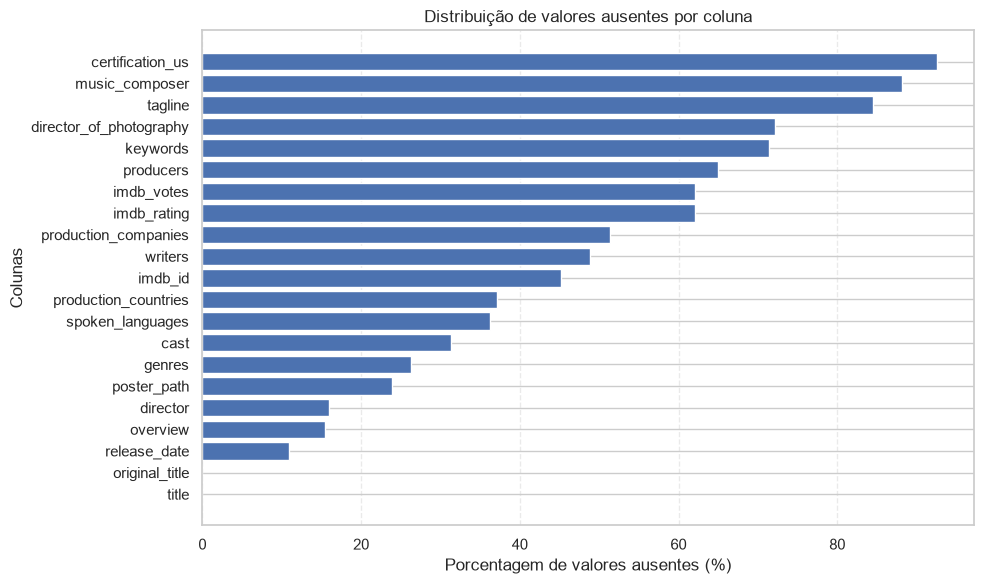

In [30]:
# Calcula a porcentagem de valores ausentes por coluna
ausentes = df.isna().sum()
percentual_ausentes = (ausentes / len(df)) * 100

# Mantém apenas as colunas que possuem valores ausentes
percentual_ausentes = percentual_ausentes[percentual_ausentes > 0]

# Ordena os valores
percentual_ausentes = percentual_ausentes.sort_values()

# Cria o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    percentual_ausentes.index,
    percentual_ausentes.values
)

plt.xlabel("Porcentagem de valores ausentes (%)")
plt.ylabel("Colunas")
plt.title("Distribuição de valores ausentes por coluna")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

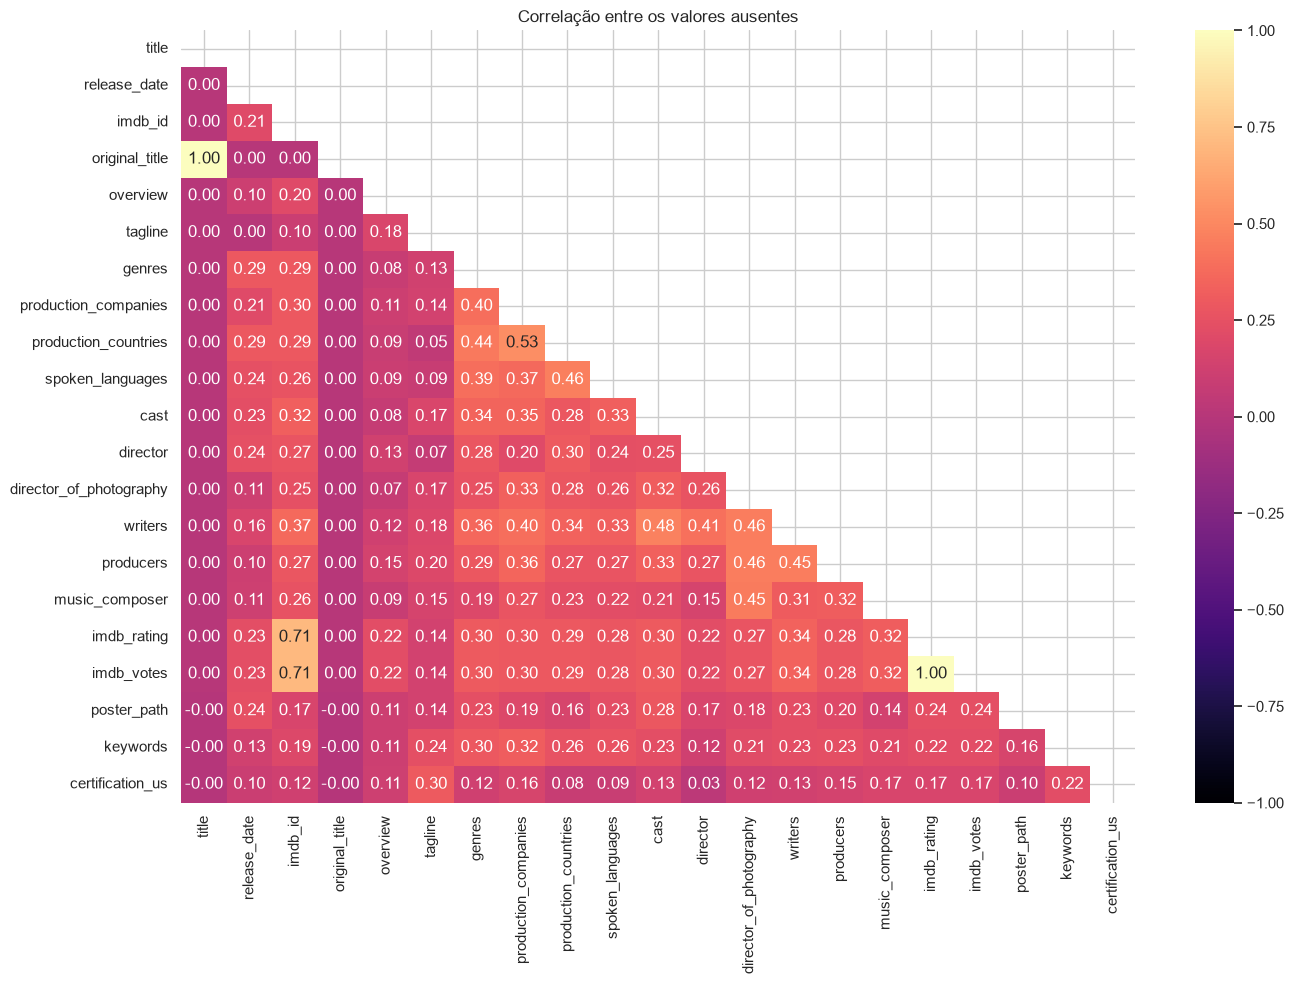

In [31]:
# Verifica quais valores estão ausentes
dados_ausentes = df[cols_com_ausentes].isna()

# Calcula a correlação entre as ausências
correlacao_ausentes = dados_ausentes.corr()

# Cria máscara para ocultar o triângulo superior
mascara = np.triu(np.ones_like(correlacao_ausentes, dtype=bool))

# Cria o gráfico
fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(
    correlacao_ausentes,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="magma",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlação entre os valores ausentes")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

* Original_titlw e title: 1.0
* Imdb_votes e imdb_rating: 1.00
* Imdb_rating e imdb_id: 0.71
* Imdb_votes e imdb_id: 0.71

São MNAR


In [32]:
VARS_QUANT = [
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity",
    "imdb_rating",
    "imdb_votes"
]

VARS_QUALI = [
    "title",
    "status",
    "release_date",
    "original_language",
    "original_title",
    "overview",
    "tagline",
    "genres",
    "production_companies",
    "production_countries",
    "spoken_languages",
    "cast",
    "director",
    "director_of_photography",
    "writers",
    "producers",
    "music_composer",
    "poster_path",
    "keywords",
    "certification_us"
]

VARS_QUALI_ALTA=["id","imdb_id"]

In [33]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
vote_average,2.06,0.00,3.14,0.00,10.00,1.10,-0.35
vote_count,22.43,0.00,370.62,0.00,41977.00,41.58,2419.27
revenue,670301.27,0.00,16747242.19,-12.00,2942661253.00,59.94,5573.87
runtime,43.25,20.00,53.90,0.00,14400.00,44.58,10022.96
budget,269583.80,0.00,4787949.82,0.00,999999999.00,42.91,3645.55
popularity,0.75,0.60,1.97,0.00,1233.78,238.39,127546.02
imdb_rating,6.25,6.40,1.33,1.00,10.00,-0.42,0.36
imdb_votes,2791.47,58.00,32684.47,5.00,3266856.00,34.22,1830.68


As variáveis: vote_average, vote_count, revenue, runtime, budget, popularity, imdb_votes possuem skewness acima de 1

As variáveis: vote_count, revenue, runtime, budget, popularity, imdb_votes possuem kurtosis acima de 2



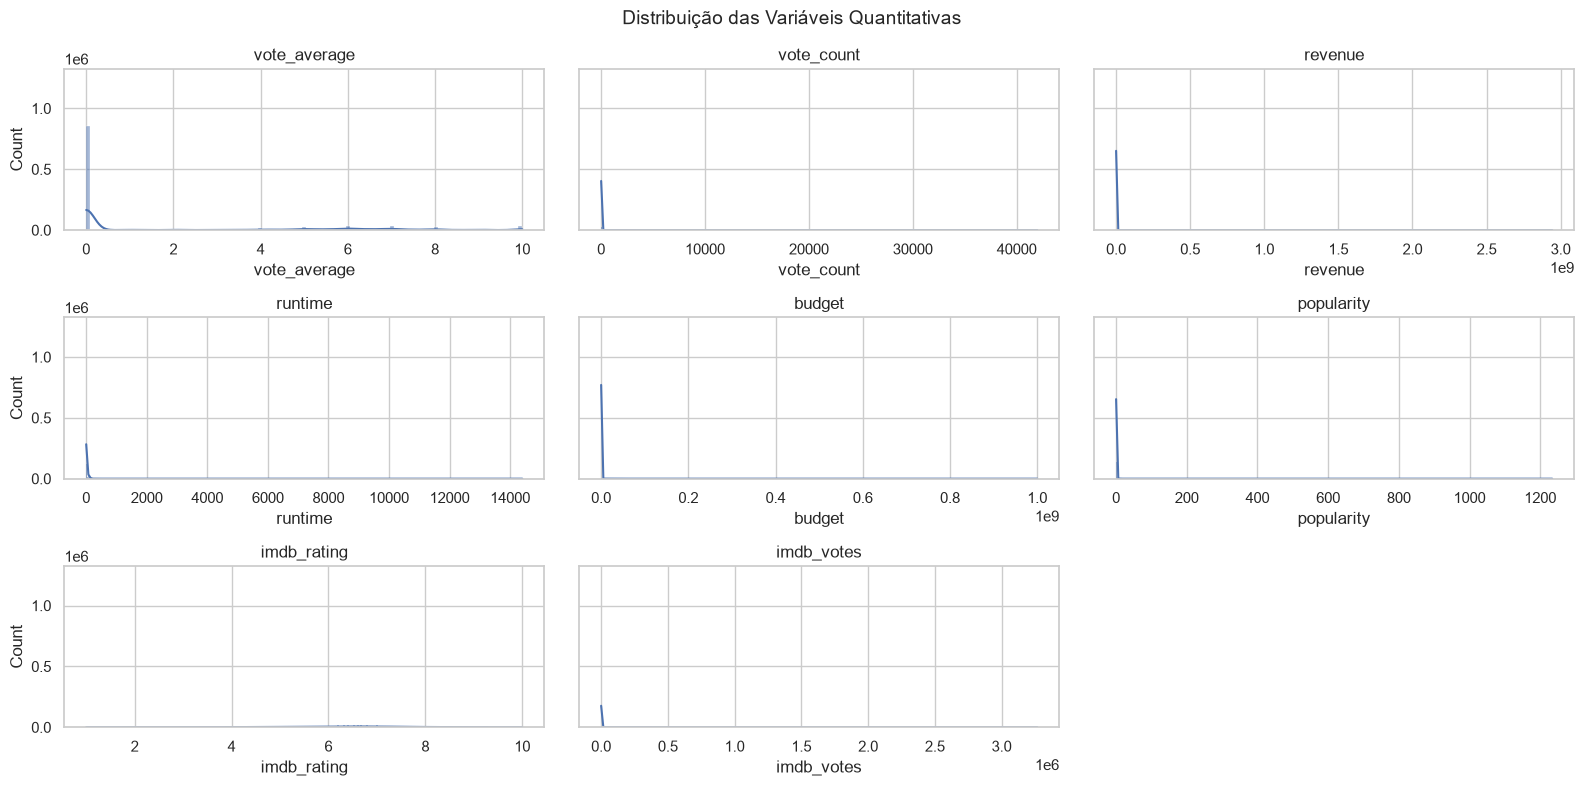

In [34]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color="#4C72B0", ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas", fontsize=14)
plt.tight_layout()
plt.show()

Melhorando a visualização dos gráficos

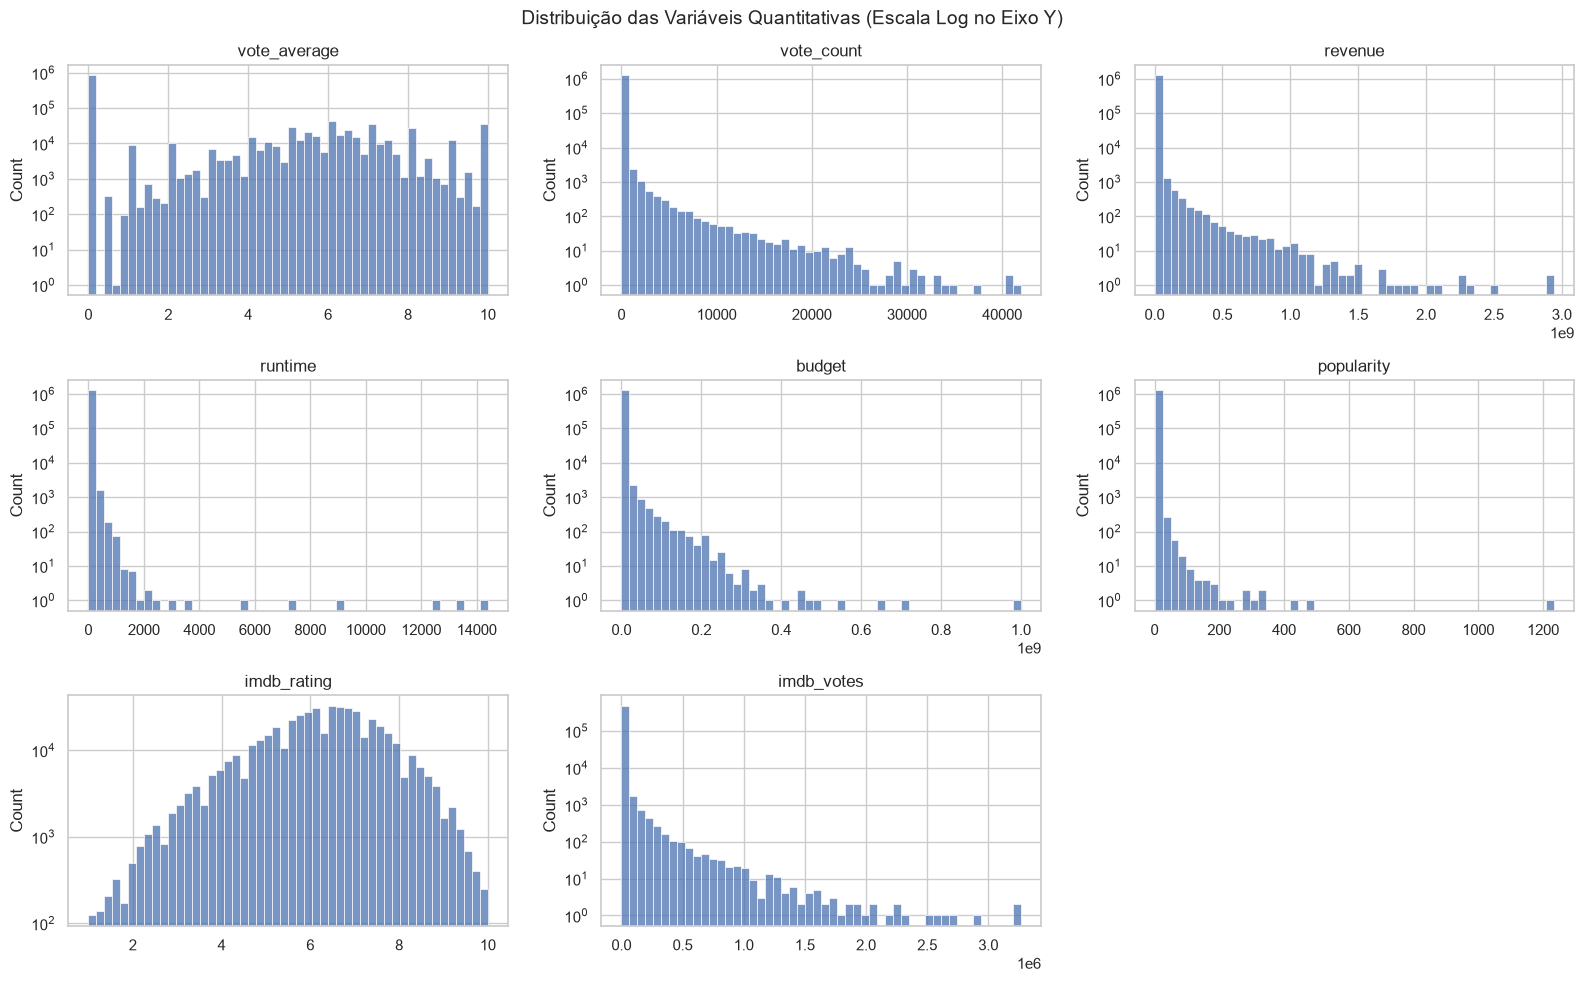

In [35]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10)) # Removido sharey=True
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, bins=50, color="#4C72B0", ax=axes[i])
    axes[i].set_yscale("log") # Escala log no eixo Y para lidar com o pico de zeros
    axes[i].set_title(col)
    axes[i].set_xlabel("") # Remove label redundante abaixo de cada gráfico

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas (Escala Log no Eixo Y)", fontsize=14)
plt.tight_layout()
plt.show()

In [36]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
vote_average,9.860000e+00,3.14,5.00
vote_count,1.373603e+05,370.62,1.00
revenue,2.804701e+14,16747242.19,0.00
runtime,2.904780e+03,53.90,82.00
budget,2.292446e+13,4787949.82,0.00
popularity,3.890000e+00,1.97,0.81
imdb_rating,1.760000e+00,1.33,1.60
imdb_votes,1.068274e+09,32684.47,239.00


In [37]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- title ---
                                                    absoluta  relativa
title                                                                 
Home                                                     208       0.0
Untitled                                                 163       0.0
Mother                                                   137       0.0
Alone                                                    131       0.0
Echo                                                     110       0.0
...                                                      ...       ...
" ONLYFANS MANAGERS,  les nouveaux agents du X"            1       0.0
Balcony@Guide-Can I upgrade to a balcony on Vik...         1       0.0
Balcony@Guide-Can I upgrade to a balcony on Mar...         1       0.0
Balcony@Guide-Can I upgrade to a balcony on Win...         1       0.0
【Expert™Guide】How do I add a cabin on a Silvers...         1       0.0

[1072995 rows x 2 columns]

--- status ---
                 a

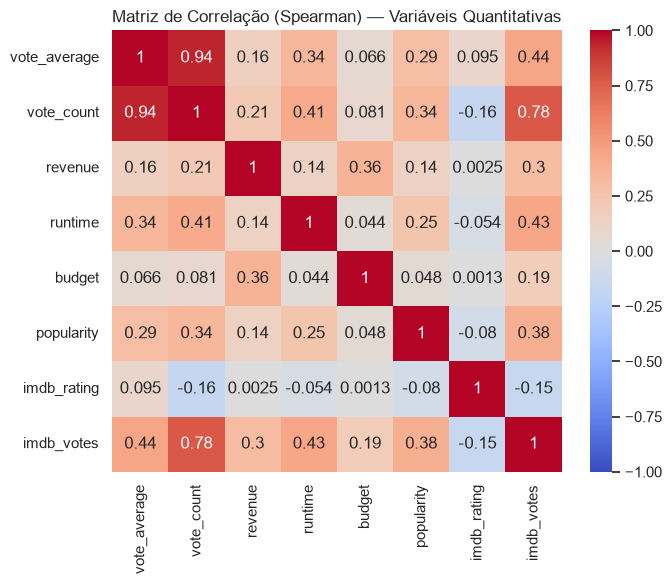

In [38]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

vote_count e vote_average = 0.94

imdb_votes e vote_count = 0.78


In [39]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
vote_average,-7.50,12.50,0.0
vote_count,-1.50,2.50,221735.0
revenue,0.00,0.00,29336.0
runtime,-121.00,207.00,5438.0
budget,0.00,0.00,87830.0
popularity,-1.12,2.12,69537.0
imdb_rating,3.10,9.50,10717.0
imdb_votes,-338.50,617.50,75484.0


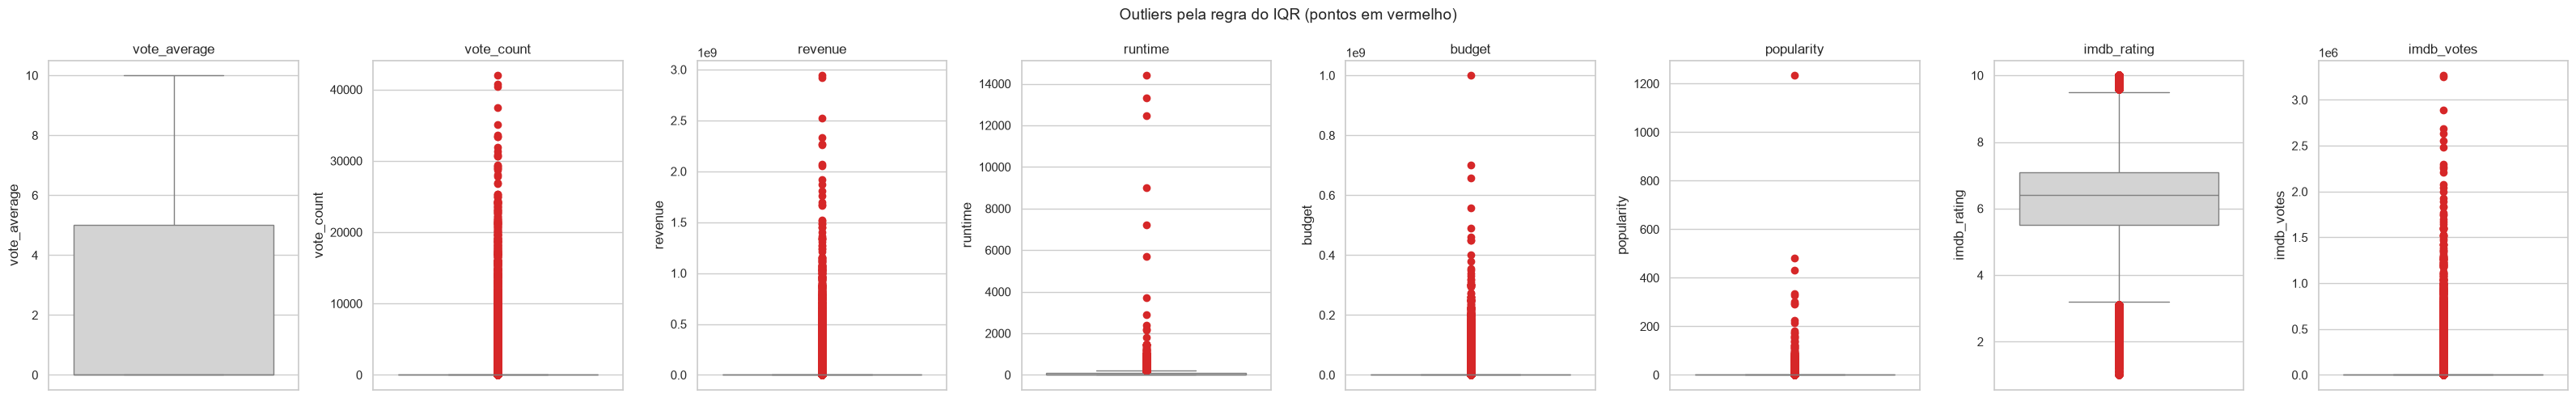

In [40]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Como o grafo vai seguir essas regras:

Vértices: filmes

Direção: do filme mais antigo -> filme mais recente

Conexão: Se houver atores em comum

Peso: imdb_rating do mais atual - imdb_rating do mais antigo

Decidimos remover as linhas que possuem essas colunas em branco para depois analisar novamente nosso dataset

Variáveis que não podem estar em branco: title, release_date, imdb_rating, cast
